# Segmentation

Note that for this example we assume the passive properties of the cell are known and do not need to be estimated.

In [1]:
import sys
sys.path.append("../")

import numpy as np
import matplotlib.pyplot as plt

import act.modfiles
from act.segmentation import ACTSegmenter

from act.simulator import ACTSimulator
from act.cell_model import ACTCellModel
from act.data_processing import find_events
from act.types import SimulationParameters, ConstantCurrentInjection

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64



## Define the channels based on the modfile

We first define modfiles as `python` objects using the `ACTModfile` class.
1. Choose the channels for segmentation (Na, K).

For each channel:

2. Transfer the channel name (`channel_name`), channel ion (`ion`), maximum conductance (`gbar`) and channel reversal potential (`e`) from the modfile.
3. 
   Define the channel's state variables. Use `act.modfiles.StateVariable` for variables that do not need to be segmented (typically, inactivation functions) and `act.modfiles.SegmentableStateVariable` for variables that need to be segmented.

   For each variable, Transfer the name (`name`), the power of the variable in the conductance equation (`power`), $V_{1/2}$ (`vhalf`) and $k$ (`k`) from the modfile. The `tau` parameter is not considered during segmentation and can be set to `None`.

   For `SegmentableStateVariable`s, specify the bounds for `vhalf` and `k`. Note that we are not using the full biological range for `vhalf` of Na activation function to achieve a closer match between the original and segmented cell.

In [ ]:
Na = act.modfiles.ACTModfile(
    channel_name = "Na",
    ion = "na",
    gbar = 0.12,
    e = 50,
    state_variables = [
        act.modfiles.SegmentableStateVariable(
            name = "m",
            power = 3, # m * m * m
            vhalf = -39.57,
            k = 9.55,
            tau = None,
            segmentation_vhalf_bounds = (-45, -40),
            segmentation_k_bounds = (5, 10)
        ),
        act.modfiles.StateVariable(
            name = "h",
            power = 1,
            vhalf = -60,
            k = -6,
            tau = None,
        )
    ]
)

K = act.modfiles.ACTModfile(
    channel_name = "K",
    ion = "k",
    gbar = 0.036,
    e = -77,
    state_variables = [
        act.modfiles.SegmentableStateVariable(
            name = "n",
            power = 4, # n * n * n * n
            vhalf = -50.98,
            k = 17.44,
            tau = None,
            segmentation_vhalf_bounds = (-55, -35),
            segmentation_k_bounds = (10, 20)
        )
    ]
)

## Run `ACTSegmenter`

In [ ]:
# Assumed to be known in this example
V_rest = -65

The spiker model has only 2 modules: passive (voltages below $V_{rest}$) and spiking (voltages above $V_{rest}$). Consequently, in this case the threshold voltage is known and equal to $V_{rest}$. We can use `ACTSegmenter`'s `segment_v()` function to segment at this threshold value.

In [ ]:
segmenter = ACTSegmenter()
segmenter.segment_v(modfile_group = [Na, K], v_threshold = V_rest)

--------------------
Segmentation results
--------------------
Module voltage cutoff: -65 mV

Estimated parameters for activation functions:
Na(m): vhalf = -40.0 mV, k = 5.0 mV
K(n): vhalf = -35.0 mV, k = 10.0 mV


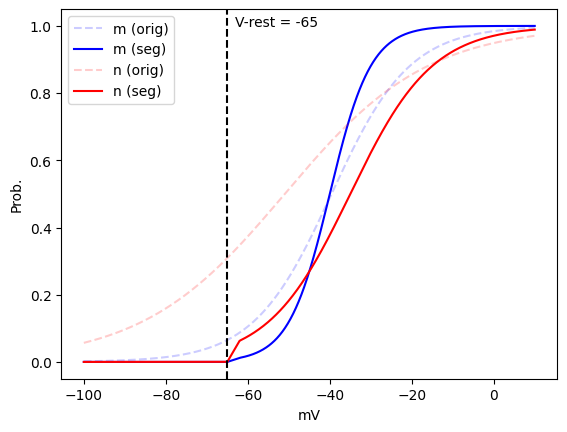

In [199]:
fig, ax = plt.subplots(1, 1)
ca = ax

v = np.linspace(-100, 10, 1000)

for var, var_color in zip([Na["m"], K["n"]], ["blue", "red"]):
    ca.plot(v, var.activation_function(v), label = f"{var.name} (orig)", color = var_color, alpha = 0.2, ls = "--")
    ca.plot(v, var.segmented_activation_function(v), label = f"{var.name} (seg)", color = var_color)

ca.set_xlabel("mV")
ca.set_ylabel("Prob.")
ca.axvline(V_rest, ls = "--", color = "black")
ca.text(V_rest + 2, 1.0, f"V-rest = {V_rest}")

ca.legend();

## Update the modfile

Defining modfiles as `ACTModfile` objects allows us to easily obtain the segmented activation functions as shown below.

In [200]:
print(Na.compose_segmented_activation_function(svar = Na["m"]))


	:Segmentation-start
	minf = 1.0 / (1.0 + exp(-(v - -40.0) / 5.0))
	if (v < -62) {
		minf = 0.26164 + v * 0.00403
	}
	if (v < -65) {
		minf = 0
	}
	:Segmentation-end



In [201]:
print(K.compose_segmented_activation_function(svar = K["n"]))


	:Segmentation-start
	ninf = 1.0 / (1.0 + exp(-(v - -35.0) / 10.0))
	if (v < -62) {
		ninf = 1.36161 + v * 0.02095
	}
	if (v < -65) {
		ninf = 0
	}
	:Segmentation-end



Copy the printouts into the `modfiles/seg/hh_spiker.mod`. E.g., for Na:

![](spiker_img2.png)

## Simulate and compare

Finally, we simulate from both the original and segmented cell and compare the voltage traces and the FI curve. 

In [ ]:
original_cell = ACTCellModel(
    path_to_hoc_file = "./spiker/orig/template.hoc",
    cell_name = "Spiker",
    path_to_mod_files = "./spiker/orig/modfiles",
    passive = ["gl_hh_spiker", -54.4, None],
    active_channels = ["gnabar_hh_spiker", "gkbar_hh_spiker"]
)

segmented_cell = ACTCellModel(
    path_to_hoc_file = "./spiker/seg/template.hoc",
    cell_name = "Spiker",
    path_to_mod_files = "./spiker/seg/modfiles",
    passive = ["gl_hh_spiker", -54.4, None],
    active_channels = ["gnabar_hh_spiker", "gkbar_hh_spiker"]
)

In [213]:
simulator = ACTSimulator()

I = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09]
for sim_idx, i_amp in enumerate(I):
    simulator.submit_job(
        original_cell, 
        SimulationParameters(
            sim_idx = sim_idx,
            sim_name = "spiker_orig",
            h_celsius = 6.3, 
            h_v_init = -90,
            h_tstop = 1000,
            CI = [ConstantCurrentInjection(amp = i_amp, dur = 800, delay = 100)]
        )
    )

simulator.run_jobs()


        ACTSimulator (2025)
        ----------
        When submitting multiple jobs, note that the cells must share modfiles.
        


libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64



In [214]:
simulator = ACTSimulator()

I = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09]
for sim_idx, i_amp in enumerate(I):
    simulator.submit_job(
        segmented_cell, 
        SimulationParameters(
            sim_idx = sim_idx,
            sim_name = "spiker_seg",
            h_celsius = 6.3, 
            h_v_init = -90,
            h_tstop = 1000,
            CI = [ConstantCurrentInjection(amp = i_amp, dur = 800, delay = 100)]
        )
    )

simulator.run_jobs()


        ACTSimulator (2025)
        ----------
        When submitting multiple jobs, note that the cells must share modfiles.
        


libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64

libnrniv.dylib running as arm64
but /usr/local/lib/libmpi.dylib can only run as x86_64



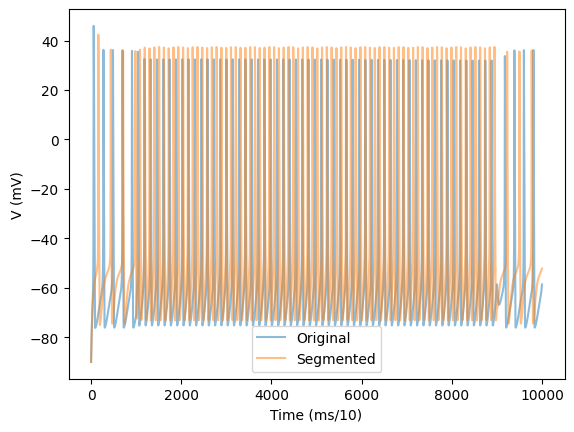

In [215]:
# Read the data
v_orig = np.load("spiker_orig/out_7.npy")[:, 0]
v_seg = np.load("spiker_seg/out_7.npy")[:, 0]

fig, ax = plt.subplots(1, 1)
ca = ax
T = range(len(v_orig))

ca.plot(T, v_orig, alpha = 0.5, label = "Original")
ca.plot(T, v_seg, alpha = 0.5, label = "Segmented")
ca.set_xlabel("Time (ms/10)")
ca.set_ylabel("V (mV)")

ca.legend();

Text(0, 0.5, 'V (mV)')

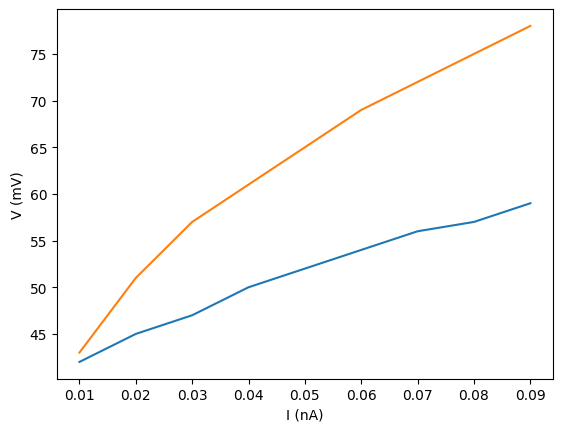

In [7]:
f_orig = []
f_seg = []

for sim_idx in range(len(I)):
    f_orig.append(len(find_events(np.load(f"spiker_orig/out_{sim_idx}.npy")[1000:9000, 0], 0)))
    f_seg.append(len(find_events(np.load(f"spiker_seg/out_{sim_idx}.npy")[1000:9000, 0], 0)))

plt.plot(I, f_orig, label = "Original")
plt.plot(I, f_seg, label = "Segmented")
plt.xlabel("I (nA)")
plt.ylabel("V (mV)")

As we can see, although a particular trace matches fairly closely, the FI curve for the segmented cell is off. This is expected, since we adjusted $V_{1/2}$ and $k$, and these changes need to be compensated by adjusting conductances.